In [ ]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

Question 1

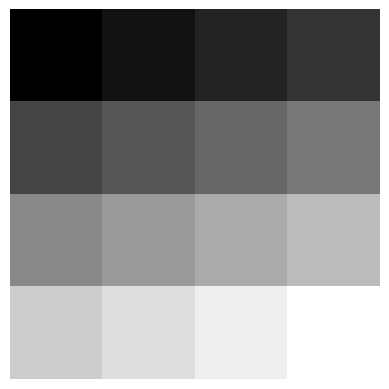

In [ ]:
I = np.array([
    [10,20,30,40],
    [50,60,70,80],
    [90,100,110,120],
    [130,140,150,160]
])
plt.imshow(I,cmap='gray');
plt.axis('off');


Sobel Operator Kernels

In [ ]:
S_x = np.array([
    [-1, 0 ,1],
    [-2,0,2],
    [-1,0,1]
])
S_y = S_x.T

print(S_x)
print(S_y)


[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]
[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]


Sobel kernel convoled with the image to produce the image gradients

In [ ]:

G_x = sp.signal.convolve2d(I,S_x,mode='valid')
G_y = sp.signal.convolve2d(I,S_y,mode='valid')

print(G_x)
print(G_y)


[[-80 -80]
 [-80 -80]]
[[-320 -320]
 [-320 -320]]


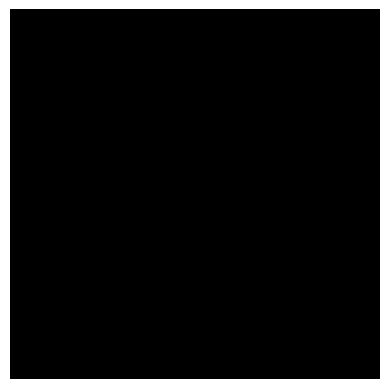

In [ ]:
grad_mag = np.sqrt(G_x**2 + G_y**2)
grad_mag = grad_mag/np.max(grad_mag)
grad_dir = np.arctan2(G_y,G_x)

threshold = 0.8
edges = (grad_mag > threshold).astype(np.uint8) * 255
plt.imshow(edges,cmap='gray');
plt.axis('off');

# Question 2
Harris Corner Detection

In [ ]:
G_x2 = G_x ** 2
G_y2 = G_y ** 2
G_xy = G_x * G_y



In [ ]:
Sxx = gaussian_filter(G_x2, sigma=1)
Syy = gaussian_filter(G_y2, sigma=1)
Sxy = gaussian_filter(G_xy, sigma=1)

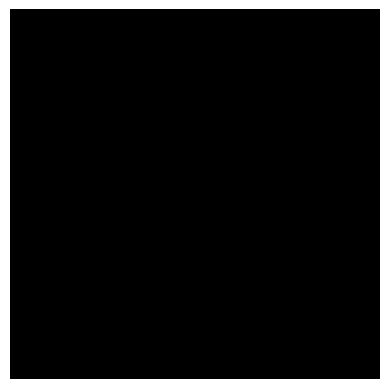

In [ ]:
alpha = 0.04  # somewhere in 0.04-0.06

det_M = Sxx * Syy - Sxy ** 2
trace_M = Sxx + Syy

R = det_M - alpha * (trace_M ** 2)

threshold = 0.01 * R.max()  # common heuristic
corners = R > threshold
corners = corners.astype(np.uint8) * 255
plt.imshow(corners,cmap='gray');
plt.axis('off');


Question 3.

In [ ]:
x_train = np.random.rand(60000, 784)
y_train = np.random.randint(0, 10, 60000)
x_test = np.random.rand(10000, 784)

weights = np.random.rand(10, 784)
bias = np.random.rand(10)


def linear_classifier_cross_entropy(x_train, y_train, x_test, weights, bias):
    N = x_train.shape[0]

    scores = x_train @ weights.T + bias

    exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
    probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    correct_class_probs = probs[np.arange(N), y_train]
    loss = -np.mean(np.log(correct_class_probs))

    return loss

average_loss = linear_classifier_cross_entropy(x_train, y_train, x_test, weights, bias)
print(f"Average loss: {average_loss}")

Average loss: 7.031416081619387
